# Compute Data Flow

This example estimates the latency of a concept's observations from the flow of its data: each satellite generates data, stores it, and sends it to the ground over links whose rates come from coarse link budgets, sharing the antennas of ground stations and, optionally, of a data relay. Compared with latency by timing alone (see *Compute Latency*), the data flow shows when a downlink is too slow or a network too busy to keep up with the data, and what a relay adds.

The concept is a constellation of six small satellites with an optical imager, downlinking in X-band to the antennas of KSAT that NASA's Near Earth Network uses, and later adding a Ka-band crosslink to the Tracking and Data Relay Satellites (TDRS), both from the system catalog.

In [1]:
from datetime import datetime, timedelta, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tatc import utils

start = datetime(2026, 3, 1, tzinfo=timezone.utc)
end = start + timedelta(days=1)

## The concept

The imager generates data at 80 Mbit/s while it observes (`InstrumentResources.data_rate`). It observes only over the daylit half of each orbit, half of that time (`DataGeneration`), which is the average volume the satellites generate. Each satellite stores up to 1 Tbit (`SpacecraftResources.storage`).

The X-band transmitter is given by the few values known at this stage: 2 W into an antenna of 6 dBi, 2 dB of losses, and the modes of DVB-S2 at 50 Msymbol/s, the fastest of which closes with a margin of 3 dB (the default) and 1 dB of implementation loss.

In [2]:
from tatc.schemas import (
    CircularOrbit,
    DataGeneration,
    Instrument,
    InstrumentResources,
    SpacecraftCommunications,
    SpacecraftResources,
    Transmitter,
    WalkerConstellation,
)

imager = Instrument(
    name="imager",
    field_of_regard=utils.swath_width_to_field_of_regard(550e3, 300e3),
    req_target_sunlit=True,
    resources=InstrumentResources(data_rate=80e6),
)
x_band = Transmitter(
    name="X-band downlink",
    band="X",
    power=2,
    antenna_gain=6,
    losses=2,
    modes=utils.get_link_modes("dvb-s2", 50e6, implementation_loss=1),
)
generation = DataGeneration(activity="day", duty_cycle=0.5)
constellation = WalkerConstellation(
    name="sat",
    orbit=CircularOrbit(altitude=550e3, inclination=97.6, epoch=start),
    number_satellites=6,
    number_planes=3,
    instruments=[imager],
    resources=SpacecraftResources(storage=1e12),
    communications=SpacecraftCommunications(
        transmitters=[x_band], generation=generation
    ),
)
print(f"EIRP: {utils.get_eirp(x_band):.1f} dBW")

EIRP: 9.0 dBW


## The ground network

The catalog's Near Earth Network gives the position, G/T, and maximum rate of each antenna, from NASA's users' guide. Its `ksat` configuration selects the six antennas of Kongsberg Satellite Services at Svalbard, TrollSat, and Singapore. Each station is one antenna, which receives from one satellite at a time.

In [3]:
from tatc.catalog import get_system

ksat = get_system("near_earth_network").build("ksat")
pd.DataFrame(
    [
        {
            "station": station.name,
            "latitude": station.latitude,
            "X-band G/T (dB/K)": station.communications.receivers[1].g_over_t,
            "max rate (Mbit/s)": station.communications.receivers[1].max_data_rate / 1e6,
        }
        for station in ksat
    ]
)

C:\Users\pgrogan1\AppData\Local\Temp\ipykernel_9264\2659115778.py:3: UserWarning: near_earth_network:ksat is nominal, not validated: horizontal_error_p95: not tested; reference_matched: not tested; no comparison with reference data
  ksat = get_system("near_earth_network").build("ksat")


,station,latitude,X-band G/T (dB/K),max rate (Mbit/s)
0,SG1,78.231000,36.8,320.0
1,SG2,78.230000,35.7,150.0
2,SG3,78.229700,37.8,470.0
3,TR2,-72.002222,32.0,470.0
4,TR3,-72.002147,32.0,470.0
5,SI1,1.396200,35.4,470.0


The rate of the link depends on the distance and elevation of the satellite seen from a station (`utils.compute_link_rate`): free-space path loss and the atmosphere's loss (scaled from its attenuation at zenith) set the carrier to noise density, and the fastest mode that closes sets the rate. At SG3 (G/T 37.8 dB/K), the link closes at about 200 Mbit/s even at the 5 degree horizon, and reaches the fastest mode (about 220 Mbit/s) above 10 degrees; SG2's demodulator accepts at most 150 Mbit/s, so satellites prefer the other antennas at Svalbard.

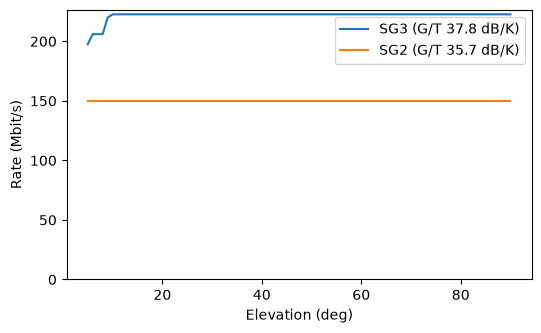

In [4]:
radius, altitude = 6378e3, 550e3
elevation = np.linspace(5, 90, 86)
angle = np.radians(elevation)
distance = np.sqrt((radius + altitude) ** 2 - (radius * np.cos(angle)) ** 2) - radius * np.sin(
    angle
)
fig, ax = plt.subplots(figsize=(6, 3.5))
for name in ["SG3", "SG2"]:
    receiver = next(s for s in ksat if s.name == name).communications.receivers[1]
    rate = utils.compute_link_rate(x_band, receiver, distance, elevation)
    ax.plot(elevation, rate / 1e6, label=f"{name} (G/T {receiver.g_over_t} dB/K)")
ax.set_xlabel("Elevation (deg)")
ax.set_ylabel("Rate (Mbit/s)")
ax.set_ylim(0, None)
ax.legend()
plt.show()

## Latency by timing alone and through the data flow

The architecture holds the constellation and the stations. With a `DataFlow` model, `evaluate_architecture` schedules the links cell by cell of a grid of time (30 s by default): each station's antenna serves one satellite at a time (the satellite that has waited longest first), a link lasts until the satellite's storage empties, and each observation's data reaches the ground when the data generated up to it is delivered, first in, first out. Without one, each observation is downlinked by timing alone at its next contact, whatever the volume of data.

In [5]:
from tatc.analysis import evaluate_architecture
from tatc.generation import generate_points_fibonacci_lattice
from tatc.schemas import Architecture, DataFlow

points = generate_points_fibonacci_lattice(count=200)


def metrics(observations):
    latency = observations["latency"] / timedelta(minutes=1)
    return {
        "mean latency (min)": latency.mean(),
        "90th percentile latency (min)": latency.quantile(0.9),
        "lost (%)": 100 * observations["lost"].mean() if "lost" in observations else 0.0,
    }


architecture = Architecture(satellites=[constellation], ground_stations=ksat)
timing = evaluate_architecture(architecture, points, start, end, metrics)
flow = evaluate_architecture(
    architecture, points, start, end, metrics, data_flow=DataFlow()
)
pd.DataFrame({"timing alone": timing.metrics, "data flow": flow.metrics})

,timing alone,data flow
mean latency (min),26.136261,31.543439
90th percentile latency (min),53.583117,61.326974
lost (%),0.000000,0.000000


Latencies through the data flow are longer than by timing alone: an observation's data waits for the data stored before it to be delivered, a pass is not long enough to empty a satellite's storage, and a station serves one satellite at a time.

The data flow's result (`flow.flow`) summarizes the volumes of each satellite, the storage over time, the links taken, and the use of each station. The busiest antenna (TR2, the only southern polar station) is taken a quarter of the day; the satellites end the day with some data still stored.

In [6]:
summary = flow.flow.summary.set_index("satellite")
(summary[["generated", "delivered", "lost", "peak_backlog", "final_backlog"]] / 1e9).round(1).rename(
    columns=lambda column: f"{column} (Gbit)"
)

,generated (Gbit),delivered (Gbit),lost (Gbit),peak_backlog (Gbit),final_backlog (Gbit)
satellite,,,,,
sat 1,1736.4,1665.6,0.0,135.3,70.8
sat 2,1719.6,1719.6,0.0,110.4,0.0
sat 3,1718.4,1711.4,0.0,111.6,7.0
sat 4,1737.6,1666.8,0.0,111.6,70.8
sat 5,1722.0,1608.0,0.0,115.2,114.0
sat 6,1737.6,1696.8,0.0,115.2,40.8


In [7]:
flow.flow.utilization[["ground_station", "antennas", "busy_fraction"]].round(3)

,ground_station,antennas,busy_fraction
0,SG1,1,0.112
1,SG2,1,0.003
2,SG3,1,0.187
3,TR2,1,0.229
4,TR3,1,0.114
5,SI1,1,0.098


## Adding a data relay

The catalog's TDRS system gives the single access service of its satellites: two antennas on each satellite, with the G/T and maximum rate of each band (`build_relay(service="single_access")`). The satellites gain a Ka-band crosslink: 10 W into a 0.5 m dish, with the modes of DVB-S2 at 100 Msymbol/s. Over the 36,000 to 42,000 km to a relay satellite, the link closes at about 180 to 200 Mbit/s.

The relay is a candidate added to the architecture (`add_one`). Only the relay's contacts are analyzed: the observations and contacts with the stations are reused, as the satellites differ only in their communications.

In [8]:
ka_crosslink = Transmitter(
    name="Ka-band crosslink",
    link="crosslink",
    band="Ka",
    power=10,
    antenna_diameter=0.5,
    losses=2,
    modes=utils.get_link_modes("dvb-s2", 100e6, implementation_loss=1),
)
relaying = constellation.model_copy(
    update={
        "communications": SpacecraftCommunications(
            transmitters=[x_band, ka_crosslink], generation=generation
        )
    }
)
relay = get_system("tdrs").build_relay(
    service="single_access", min_grazing_altitude=100e3
)
base = evaluate_architecture(
    Architecture(satellites=[relaying], ground_stations=ksat),
    points,
    start,
    end,
    metrics,
    data_flow=DataFlow(),
)
base.add_one([relay]).T

C:\Users\pgrogan1\github\tatc\src\tatc\catalog\system_schemas.py:1252: UserWarning: tdrs:slot is nominal, not validated: slot_longitude_error_p95: not tested; inclination_error_p95: not tested; test_sets: not tested; test_span_days: not tested; no comparison with reference data
  satellites = self.build(


member,tdrs
kind,relay
mean latency (min),0.281031
90th percentile latency (min),0.359782
lost (%),0.0
mean latency (min) contribution,-31.262409
90th percentile latency (min) contribution,-60.967192
lost (%) contribution,0.0


With the relay, most data flows through TDRS as it is generated, and latency falls from about half an hour to under a minute. Each relay satellite's two antennas are shared by the six satellites, and the relay's busiest satellite is taken about 60% of the time, so a larger constellation (or the relay's other users, which are not modeled) would contend for them.

In [9]:
with_relay = base.with_members(relay)
with_relay.flow.utilization[
    ["ground_station", "relay_satellite", "antennas", "busy_fraction"]
].round(3)

,ground_station,relay_satellite,antennas,busy_fraction
0,SG1,NaN,1,0.040
1,SG2,NaN,1,0.000
2,SG3,NaN,1,0.074
3,TR2,NaN,1,0.247
4,TR3,NaN,1,0.034
5,SI1,NaN,1,0.051
6,NaN,TDRS 11,2,0.614
7,NaN,TDRS 12,2,0.321
8,NaN,TDRS 13,2,0.544


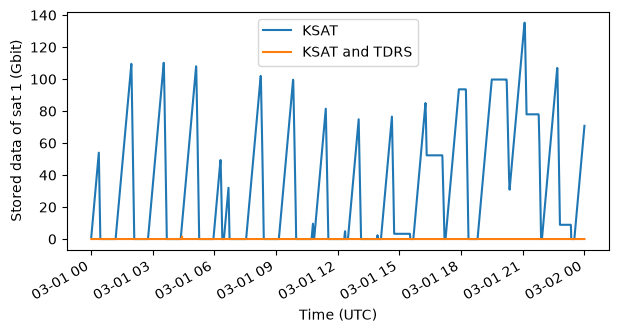

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for label, evaluation in [("KSAT", base), ("KSAT and TDRS", with_relay)]:
    storage = evaluation.flow.storage
    first = storage[storage["satellite"] == "sat 1"]
    ax.plot(first["time"], first["backlog"] / 1e9, label=label)
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Stored data of sat 1 (Gbit)")
ax.legend()
fig.autofmt_xdate()
plt.show()

## Limitations

The model is coarse, for concept studies:

- Link budgets assume clear sky (rain fades are left to the margin), fixed losses, and the fastest mode that closes; they do not model pointing, interference, or the modems' acquisition.
- Links are scheduled first come, first served on a grid of time, without the planned schedules of real networks; a relay's antennas are not shared with its other users unless fewer are given.
- An analysis starts with empty storage (`DataFlow.initial_backlog`), so analyses of at least a day are less sensitive to the start.
- Satellites without a rate of generation or a transmitter are found by timing alone.